## 1. 데이터 로딩 및 구로구 추출

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_KEY = "nosmoking_zones_seoul"

def find_repo():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        candidate = p / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾지 못했습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY

# raw_data/정답데이터, raw_data/사용데이터 및 기존 하위 폴더 지원
candidates = sorted(
    (p for p in RAW_ROOT.rglob("nosmoking_zones_seoul*.csv") if p.is_file()),
    key=lambda p: (
        p.name != "nosmoking_zones_seoul.csv",
        "사용데이터" not in p.parts,
        "정답데이터" not in p.parts,
        str(p)
    )
)
RAW_PATH = candidates[0] if candidates else None
if RAW_PATH is None:
    raise FileNotFoundError(f"원본 CSV 없음: {RAW_ROOT} 아래의 nosmoking_zones_seoul*.csv")

for encoding in ("utf-8-sig", "cp949", "euc-kr"):
    try:
        raw = pd.read_csv(
            RAW_PATH, encoding=encoding,
            dtype="string", low_memory=False
        )
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError("CSV 인코딩 확인 실패")

for col in raw.columns:
    raw[col] = raw[col].str.strip().replace("", pd.NA)

required = [
    "금연구역명", "금연구역구분", "시군구명",
    "위도", "경도", "금연구역면적", "데이터기준일자"
]
missing_cols = set(required) - set(raw.columns)
if missing_cols:
    raise ValueError(f"필수 컬럼 누락: {missing_cols}")

mask = raw["시군구명"].isin(["구로구", "서울특별시 구로구"])
selected = raw.loc[mask].copy()
selected.insert(0, "source_row_id", selected.index + 1)
selected.reset_index(drop=True, inplace=True)

if selected.empty:
    raise ValueError("구로구에 해당하는 데이터가 없습니다.")

print("원본:", RAW_PATH.name)
print("인코딩:", encoding)
print("pandas:", pd.__version__)
print("서울 전체:", raw.shape)
print("구로구:", selected.shape)
print("메모리 MB:", round(
    selected.memory_usage(deep=True).sum() / 1024**2, 3
))
print(selected.head().to_string(index=False))
print(selected.dtypes.to_string())

## 2. 결측치·중복·이상치 분석

In [2]:
missing = pd.DataFrame({
    "missing_count": selected.isna().sum(),
    "missing_pct": selected.isna().mean() * 100
})
print("\n컬럼별 결측치")
print(missing.to_string())

original_cols = [c for c in selected if c != "source_row_id"]
exact_dup = selected.duplicated(original_cols, keep=False)

lat = pd.to_numeric(selected["위도"], errors="coerce")
lon = pd.to_numeric(selected["경도"], errors="coerce")
area = pd.to_numeric(selected["금연구역면적"], errors="coerce")
fine = pd.to_numeric(selected["위반과태료"], errors="coerce")

coord_valid = (
    lat.between(33, 39) & lon.between(124, 132)
).fillna(False)

coord_dup = (
    pd.DataFrame({"lat": lat, "lon": lon})
    .duplicated(keep=False)
    & lat.notna() & lon.notna()
)

name_address_cols = [
    "금연구역명", "소재지도로명주소", "소재지지번주소"
]
name_address_dup = selected.duplicated(
    name_address_cols, keep=False
)

dates = pd.to_datetime(
    selected["데이터기준일자"],
    format="%Y-%m-%d", errors="coerce"
)

print("\n완전 중복 행:", int(exact_dup.sum()))
print("좌표 반복 행:", int(coord_dup.sum()))
print("고유 좌표 수:", len(
    pd.DataFrame({"lat": lat, "lon": lon}).drop_duplicates()
))
print("금연구역명+주소 반복 행:", int(name_address_dup.sum()))
print("광범위 좌표 오류:", int((~coord_valid).sum()))
print("날짜 오류:", int(dates.isna().sum()))
print("면적 0인 행:", int(area.eq(0).sum()))
print("\n수치형 기술통계")
print(pd.DataFrame({
    "latitude": lat,
    "longitude": lon,
    "area": area,
    "fine": fine
}).describe().to_string())

print("\n기준일자 분포")
print(selected["데이터기준일자"].value_counts().to_string())

print("\n좌표 반복 사례")
print(selected.loc[
    coord_dup,
    ["금연구역명", "금연구역구분", "위도", "경도"]
].head(15).to_string(index=False))


컬럼별 결측치
               missing_count  missing_pct
source_row_id              0     0.000000
금연구역명                      0     0.000000
금연구역범위상세                   0     0.000000
시도명                        0     0.000000
시군구명                       0     0.000000
금연구역구분                     0     0.000000
금연구역지정근거명                  0     0.000000
금연구역면적                     0     0.000000
위반과태료                      0     0.000000
위반신고전화번호                   0     0.000000
소재지도로명주소                 259    15.716019
소재지지번주소                 1111    67.415049
관리기관명                      0     0.000000
위도                         0     0.000000
경도                         0     0.000000
데이터기준일자                    0     0.000000
제공기관코드                     0     0.000000
제공기관명                      0     0.000000

완전 중복 행: 0
좌표 반복 행: 957
고유 좌표 수: 969
금연구역명+주소 반복 행: 199
광범위 좌표 오류: 0
날짜 오류: 0
면적 0인 행: 1648

수치형 기술통계
        latitude   longitude    area      fine
count     1648.0      1648.0  1648.0    164

## 3. 기초 통계 및 시각화


금연구역 유형별 등록 건수
금연구역구분
어린이놀이시설    538
버스정류소      497
어린이집       293
학교         114
금연거리        63
유치원         58
공원          57
지하철 출입구     11
교통관련시설      10
공공공지         4
광장           3
T1: 어린이놀이시설
T2: 버스정류소
T3: 어린이집
T4: 학교
T5: 금연거리
T6: 유치원
T7: 공원
T8: 지하철 출입구
T9: 교통관련시설
T10: 공공공지
T11: 광장


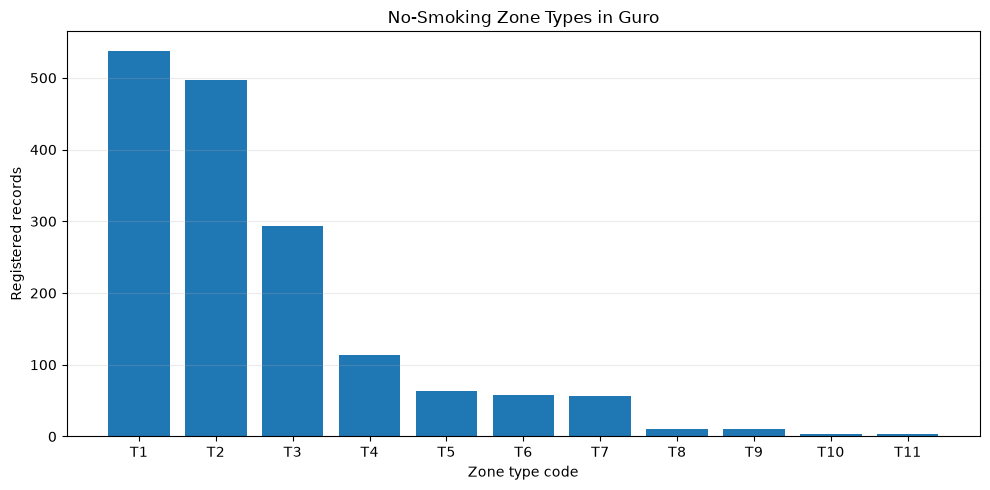

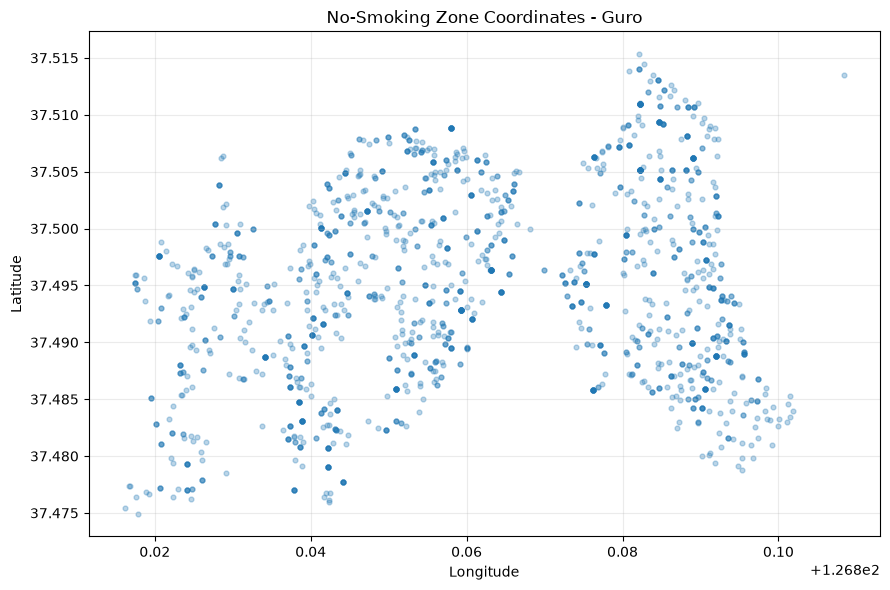

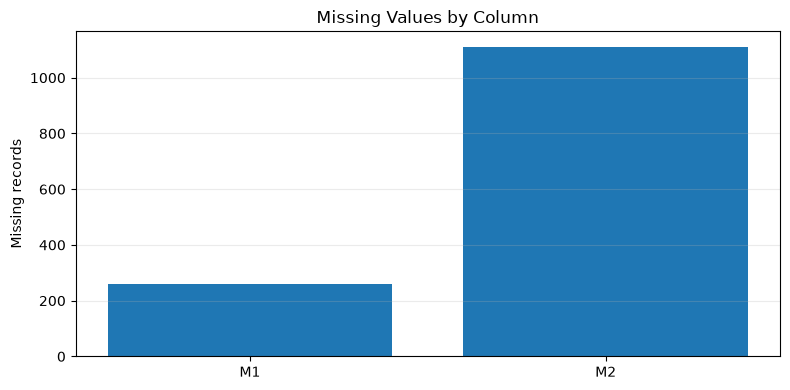

M1: 소재지도로명주소
M2: 소재지지번주소


In [3]:
type_counts = selected["금연구역구분"].value_counts()
print("\n금연구역 유형별 등록 건수")
print(type_counts.to_string())

# 유형명과 시각화용 번호 연결
type_labels = [f"T{i+1}" for i in range(len(type_counts))]
for label, category in zip(type_labels, type_counts.index):
    print(f"{label}: {category}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(type_labels, type_counts.values)
ax.set_title("No-Smoking Zone Types in Guro")
ax.set_xlabel("Zone type code")
ax.set_ylabel("Registered records")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 위도·경도 산점도: 행정경계 지도는 아님
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    lon[coord_valid], lat[coord_valid],
    s=12, alpha=0.3
)
ax.set_title("No-Smoking Zone Coordinates - Guro")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 결측 컬럼 시각화
missing_nonzero = missing.loc[missing["missing_count"] > 0]
if not missing_nonzero.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(
        range(len(missing_nonzero)),
        missing_nonzero["missing_count"]
    )
    ax.set_xticks(range(len(missing_nonzero)))
    ax.set_xticklabels([
        f"M{i+1}" for i in range(len(missing_nonzero))
    ])
    ax.set_ylabel("Missing records")
    ax.set_title("Missing Values by Column")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    for i, column in enumerate(missing_nonzero.index, 1):
        print(f"M{i}: {column}")

## 4. 데이터 전처리

In [4]:
clean = selected.copy()

for col in ["위도", "경도", "금연구역면적", "위반과태료"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

clean["데이터기준일자"] = dates.dt.strftime("%Y-%m-%d")
clean["coord_valid_broad"] = coord_valid.astype(bool).values
clean["duplicate_coordinate_flag"] = coord_dup.astype(bool).values
clean["duplicate_name_address_flag"] = (
    name_address_dup.astype(bool).values
)
clean["area_zero_flag"] = (
    clean["금연구역면적"].eq(0).fillna(False).astype(bool)
)

clean["review_needed"] = (
    ~clean["coord_valid_broad"]
    | clean["duplicate_coordinate_flag"]
    | clean["duplicate_name_address_flag"]
    | clean["데이터기준일자"].isna()
)

print("전처리 전:", selected.shape)
print("전처리 후:", clean.shape)
print("검토 필요 행:", int(clean["review_needed"].sum()))

# 중복 의심 행은 제거하지 않는다.
# 면적 0은 별도 플래그로 보존한다.

전처리 전: (1648, 18)
전처리 후: (1648, 23)
검토 필요 행: 958


## 5. summary 및 features 생성

In [5]:
records = []

def add(section, metric, category, value, unit=""):
    records.append({
        "section": section,
        "metric": metric,
        "category": category,
        "value": value,
        "unit": unit
    })

overall = {
    "source_rows": len(raw),
    "guro_rows": len(selected),
    "source_columns": len(raw.columns),
    "exact_duplicate_rows": int(exact_dup.sum()),
    "duplicate_coordinate_rows": int(coord_dup.sum()),
    "duplicate_name_address_rows": int(name_address_dup.sum()),
    "unique_coordinates": len(
        pd.DataFrame({"lat": lat, "lon": lon}).drop_duplicates()
    ),
    "invalid_coordinate_rows": int((~coord_valid).sum()),
    "area_zero_rows": int(clean["area_zero_flag"].sum()),
    "review_needed_rows": int(clean["review_needed"].sum())
}

for metric, value in overall.items():
    add("overall", metric, "", value, "records")

for category, count in type_counts.items():
    add("zone_type", "record_count", category, count, "records")

for col in original_cols:
    add(
        "missing", "count", col,
        int(selected[col].isna().sum()), "records"
    )
    add(
        "missing", "percent", col,
        float(selected[col].isna().mean() * 100), "%"
    )

for date, count in selected["데이터기준일자"].value_counts().items():
    add("date", "record_count", date, count, "records")

numeric_cols = [
    "위도", "경도", "금연구역면적", "위반과태료"
]
for col in numeric_cols:
    for statistic in ["min", "max", "mean", "median", "std"]:
        value = getattr(clean[col], statistic)()
        add("numeric", statistic, col, value)

summary = pd.DataFrame(records)

features = pd.DataFrame({
    "source_row_id": clean["source_row_id"],
    "latitude": clean["위도"],
    "longitude": clean["경도"],
    "has_road_address": clean["소재지도로명주소"].notna().astype(int),
    "has_parcel_address": clean["소재지지번주소"].notna().astype(int),
    "duplicate_coordinate_flag": clean["duplicate_coordinate_flag"],
    "review_needed": clean["review_needed"]
})

dummies = pd.get_dummies(
    clean["금연구역구분"],
    prefix="zone_type",
    dtype=int
)
features = pd.concat([features, dummies], axis=1)

print("clean:", clean.shape)
print("summary:", summary.shape)
print("features:", features.shape)
print(features.head().to_string(index=False))

clean: (1648, 23)
summary: (76, 5)
features: (1648, 18)
 source_row_id   latitude   longitude  has_road_address  has_parcel_address  duplicate_coordinate_flag  review_needed  zone_type_공공공지  zone_type_공원  zone_type_광장  zone_type_교통관련시설  zone_type_금연거리  zone_type_버스정류소  zone_type_어린이놀이시설  zone_type_어린이집  zone_type_유치원  zone_type_지하철 출입구  zone_type_학교
           571  37.505123  126.882191                 1                   0                       True           True               0             0             0                 0               0                1                  0               0              0                  0             0
           572  37.507375  126.880769                 1                   0                       True           True               0             0             0                 0               0                1                  0               0              0                  0             0
           573  37.507375  126.880769                 1 

## 6. CSV 저장·README 작성·검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "clean.csv": clean,
    "summary.csv": summary,
    "features.csv": features
}

for filename, frame in outputs.items():
    frame.to_csv(
        OUT_DIR / filename,
        index=False, encoding="utf-8-sig"
    )

loaded = {}
for filename, frame in outputs.items():
    path = OUT_DIR / filename

    # 식별자 및 코드값을 문자열로 보존
    dtype_map = {}
    if filename == "clean.csv":
        dtype_map = {
            "제공기관코드": "string",
            "위반신고전화번호": "string"
        }

    reread = pd.read_csv(
        path, encoding="utf-8-sig",
        dtype=dtype_map or None
    )

    assert reread.shape == frame.shape, filename
    assert list(reread.columns) == list(frame.columns), filename
    assert path.read_bytes().startswith(b"\xef\xbb\xbf")
    loaded[filename] = reread

assert (
    loaded["clean.csv"]["source_row_id"].tolist()
    == clean["source_row_id"].tolist()
)
assert (
    loaded["features.csv"]["source_row_id"].tolist()
    == features["source_row_id"].tolist()
)

for c in ["위도", "경도"]:
    assert np.allclose(
        loaded["clean.csv"][c].to_numpy(dtype=float),
        clean[c].to_numpy(dtype=float),
        atol=1e-9, rtol=0, equal_nan=True
    )

descriptions = {
    "source_row_id": "원본 서울 데이터에서의 행 번호",
    "금연구역명": "등록 금연구역의 명칭",
    "금연구역범위상세": "금연 지정 범위의 원본 설명",
    "시도명": "광역 행정구역",
    "시군구명": "시군구명",
    "금연구역구분": "금연구역의 시설·공간 유형",
    "금연구역지정근거명": "금연구역 지정 근거",
    "금연구역면적": "원본 면적값, 0은 실제 면적 아님",
    "위반과태료": "원본 과태료 정보",
    "위반신고전화번호": "원본 신고 전화번호",
    "소재지도로명주소": "도로명주소",
    "소재지지번주소": "지번주소",
    "관리기관명": "관리기관",
    "위도": "원본 위도",
    "경도": "원본 경도",
    "데이터기준일자": "자료 기준일",
    "제공기관코드": "자료 제공기관 코드",
    "제공기관명": "자료 제공기관명",
    "coord_valid_broad": "광범위 위경도 범위 검사 결과",
    "duplicate_coordinate_flag": "같은 좌표를 공유하는 행 여부",
    "duplicate_name_address_flag": "동일 구역명·주소 반복 여부",
    "area_zero_flag": "원본 면적이 0인지 여부",
    "review_needed": "검토 필요 여부, 흡연 위험도 아님",
    "section": "통계 종류",
    "metric": "통계 지표",
    "category": "집계 대상",
    "value": "통계값",
    "unit": "지표의 단위",
    "latitude": "원본 위도에서 변환",
    "longitude": "원본 경도에서 변환",
    "has_road_address": "도로명주소가 있으면 1",
    "has_parcel_address": "지번주소가 있으면 1"
}

def describe(c):
    if c.startswith("zone_type_"):
        return "해당 금연구역 유형이면 1, 아니면 0: " + c[10:]
    return descriptions.get(c, "컬럼 의미 확인 필요")

def esc(value):
    return str(value).replace("|", "\\|").replace("\n", " ")

lines = [
    "# 구로구 금연구역 CSV 사용 설명서",
    "",
    f"- 원본: `{RAW_PATH.name}`",
    f"- 식별자: `{DATASET_KEY}`",
    "- 분석 지역: 서울특별시 구로구",
    "- 추출 기준: `시군구명`이 `구로구` 또는 `서울특별시 구로구`",
    f"- 서울 원본: {len(raw):,}행",
    f"- 구로구 추출: {len(selected):,}행",
    "",
    "## 전처리",
    "",
    "- 문자열 앞뒤 공백 및 공란 표준화",
    "- 숫자 및 날짜 형식 변환",
    "- 원본 행 번호 보존",
    "- 중복 좌표와 동일 구역명·주소 플래그 생성",
    "- 중복 의심 행 자동 삭제 없음",
    "- 면적 0은 실제 면적으로 해석하지 않음",
    "",
    "## CSV별 컬럼 설명",
    ""
]

purposes = {
    "clean.csv": "구로구 원본 정보를 보존한 정제 데이터",
    "summary.csv": "EDA 통계 및 집계 데이터",
    "features.csv": "공간 분석·머신러닝 입력 변수 후보"
}

for filename, frame in outputs.items():
    lines += [
        f"### {filename}",
        "",
        f"**목적:** {purposes[filename]}",
        f"**크기:** {len(frame)}행 × {len(frame.columns)}열",
        "",
        "| 컬럼명 | 자료형 | 의미 |",
        "|---|---|---|"
    ]
    for col in frame.columns:
        lines.append(
            f"| `{esc(col)}` | `{frame[col].dtype}` | {esc(describe(col))} |"
        )
    lines.append("")

lines += [
    "## summary.csv 집계 기준",
    "",
    "- `overall`: 전체 규모 및 데이터 품질",
    "- `zone_type`: 유형별 등록 행 수",
    "- `missing`: 컬럼별 결측 건수·비율",
    "- `date`: 기준일자별 등록 건수",
    "- `numeric`: 수치형 기술통계",
    "",
    "## CSV 간 관계",
    "",
    "- `clean.csv`와 `features.csv`는 구로구 등록 행 단위",
    "- 두 파일은 `source_row_id`로 연결",
    "- `summary.csv`는 집계 결과로 행 단위가 다름",
    "",
    "## 사용 시 주의사항",
    "",
    "- 금연구역 위치는 실제 흡연 발생 위치가 아님",
    "- 중복 좌표만으로 중복 시설이라고 단정할 수 없음",
    "- 원본 면적값이 0이므로 면적 기반 계산에 사용 금지",
    "- 위경도 값의 공식 좌표계와 구로구 경계 확인 필요",
    "- 공통 250m 격자 및 도보 링크와 아직 결합하지 않음",
    "- 시간대별 흡연 관측값과 지도학습 정답 라벨 없음",
    "- 품질 플래그는 흡연 위험 점수가 아님",
    ""
]

readme_path = OUT_DIR / "README.md"
readme_path.write_text("\n".join(lines), encoding="utf-8")

readme = readme_path.read_text(encoding="utf-8")
for frame in outputs.values():
    for col in frame.columns:
        assert f"`{col}`" in readme

print("파일 생성 및 검증 완료")
for path in sorted(OUT_DIR.iterdir()):
    print(path.name, path.stat().st_size, "bytes")

파일 생성 및 검증 완료
clean.csv 601287 bytes
features.csv 105205 bytes
README.md 5387 bytes
summary.csv 3304 bytes
